# Auslan fingerspelling — experiment lab

A working notebook for **exploring** the pipeline: run it step by step, look at the images,
watch the runs go by, and plot the results as they land.

**This notebook drives `src/auslan/`, it does not re-implement it.** Every cell calls the same
tested code the `auslan` CLI calls, so nothing here can drift from the implementation and
nothing in the package needs changing. That keeps `src/auslan/` as the single source of truth
for the Task 2 code appendix, while this file stays a lab log.

| Step | What you get |
|---|---|
| 1–3 | Environment, settings, credential check |
| 4–5 | Download and prepare the datasets |
| 6 | **Look at the data** — class balance, hand-detection rates, sample crops, failures |
| 7 | Smoke test: one fast run end to end before committing to the full job |
| 8 | Plan E1 and run it with live progress (resumable — rerun the cell any time) |
| 9 | **Plot the results** — method comparison, the P2 vs P3 transfer effect, confusions |
| 10 | Build the report tables and copy them to `results/tong/` |

## Before you start

Launch the kernel **without letting `uv` re-sync**, or it silently reinstalls the CPU build of
torch and you lose the GPU:

- **VS Code (easiest on Windows):** open this notebook, then pick the `.venv` interpreter.
  VS Code talks to the venv python directly, so `uv` never runs.
- **JupyterLab:** `uv run --no-sync jupyter lab` — the `--no-sync` is not optional.

Cell 1 checks this and tells you if the CPU build crept back in.

In [13]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path


def find_repo_root(start: Path) -> Path:
    """Walk up until the folder containing pyproject.toml, so the notebook can live anywhere."""
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("could not find the repository root (no pyproject.toml above cwd)")


ROOT = find_repo_root(Path.cwd().resolve())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

print(f"repo root : {ROOT}")
print(f"python    : {sys.version.split()[0]}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
repo root : D:\Master degree at UTS\Study\2nd sem1\UTS Image Processing and Pattern Recognition\Assignment\Final Project\auslan-image-processing
python    : 3.12.13


## 1. Environment check

The important line is the torch build. `2.14.1+cu130` means the GPU is in play;
`2.14.1+cpu` means a plain `uv run` reverted it and training will be ~15x slower.

In [14]:
import torch

from auslan.methods.torch_base import default_device

device = default_device()
print(f"torch           : {torch.__version__}")
print(f"cuda available  : {torch.cuda.is_available()}")
print(f"default_device(): {device}")

if torch.cuda.is_available():
    properties = torch.cuda.get_device_properties(0)
    print(f"gpu             : {properties.name}  ({properties.total_memory / 1e9:.1f} GB)")
elif torch.__version__.endswith("+cpu"):
    print(
        "\n!! The CPU build of torch is installed. A plain `uv run` re-syncs from uv.lock and\n"
        "   replaces the CUDA build. Restore it from a terminal, then restart this kernel:\n\n"
        "   uv pip install --index-url https://download.pytorch.org/whl/cu130 \\\n"
        "     --reinstall-package torch --reinstall-package torchvision \\\n"
        '     "torch==2.14.1+cu130" "torchvision==0.29.1+cu130"\n'
    )

torch           : 2.14.1+cu130
cuda available  : True
default_device(): cuda
gpu             : NVIDIA GeForce RTX 4050 Laptop GPU  (6.4 GB)


## 2. Settings

`Settings` is frozen. To try different values, pass a YAML file to `load_settings` or use
`dataclasses.replace(settings, image_size=64)` — don't edit `config.py`.

In [15]:
import os

from auslan.config import load_settings

os.chdir(ROOT)  # all settings paths are relative to the repository root
settings = load_settings(None)

print(f"data_dir      : {settings.data_dir}")
print(f"artifacts_dir : {settings.artifacts_dir}")
print(f"image_size    : {settings.image_size}   (CNN input)")
print(f"crop_size     : {settings.crop_size}   (cached crop)")
print(f"seeds         : {settings.seeds}")
print(f"k_values      : {settings.k_values}")
print(f"workers       : {settings.workers}")

data_dir      : data
artifacts_dir : artifacts
image_size    : 128   (CNN input)
crop_size     : 224   (cached crop)
seeds         : (0, 1, 2)
k_values      : (5, 10, 20, 50)
workers       : 4


## 3. Credentials

**Kaggle** is required — three of the four datasets come from there. Generate a token at
*Kaggle → Settings → API → Generate New Token* and save it as
`C:\Users\<you>\.kaggle\kaggle.json`. You may also need to open the
`auslan-sign-language-fingerspelling-dataset` page once and accept its terms, or the
download returns 403.

**Roboflow** is optional but needed for P2/P3's independent test set. Set `ROBOFLOW_API_KEY`
in your shell before launching the kernel — don't paste it into a cell, or it gets saved
into the notebook file and pushed to GitHub.

In [16]:
import getpass
import os
import re
from pathlib import Path

# Read the keys from the gitignored notes file if it is there, otherwise prompt. Reading beats
# typing: a hand-paste that drops one character fails authentication with a confusing error.
# Nothing is written into the .ipynb either way — the values stay in variables.
KEYS_FILE = ROOT / "notebooks" / "api-keys.local.md"  # ignored via *.local.md
CREDENTIALS = (
    ("KAGGLE_API_TOKEN", "the three Kaggle datasets", 37),
    ("ROBOFLOW_API_KEY", "the independent Auslan test set", 20),
)


def keys_from_notes(path: Path) -> dict[str, str]:
    """Pull `VARIABLE` | `value` pairs out of the local notes table, if the file exists."""
    if not path.is_file():
        return {}
    pattern = re.compile(r"`(KAGGLE_API_TOKEN|ROBOFLOW_API_KEY)`\s*\|\s*`([^`]+)`")
    return dict(pattern.findall(path.read_text(encoding="utf-8")))


from_notes = keys_from_notes(KEYS_FILE)
print(f"notes file: {'read ' + KEYS_FILE.name if from_notes else 'not found, will prompt'}\n")

for variable, needed_for, expected in CREDENTIALS:
    # The notes file wins over an existing variable on purpose: a bad value pasted earlier
    # in this kernel would otherwise keep winning until you restarted it.
    value = from_notes.get(variable) or os.environ.get(variable)
    if not value:
        value = getpass.getpass(f"{variable} — for {needed_for} (blank to skip): ").strip()
    if not value:
        print(f"{variable}: skipped")
        continue
    os.environ[variable] = value
    warning = "" if len(value) == expected else f"  <-- expected {expected}, check for a bad paste"
    print(f"{variable}: set, {len(value)} characters{warning}")

notes file: read api-keys.local.md

KAGGLE_API_TOKEN: set, 37 characters
ROBOFLOW_API_KEY: set, 20 characters


In [17]:
kaggle_home = Path.home() / ".kaggle"
kaggle_ok = any((kaggle_home / name).exists() for name in ("kaggle.json", "access_token")) or bool(
    os.environ.get("KAGGLE_KEY") or os.environ.get("KAGGLE_API_TOKEN")
)
roboflow_ok = bool(os.environ.get("ROBOFLOW_API_KEY"))

print(f"kaggle   : {'found' if kaggle_ok else 'MISSING — step 4 will fail'}")
print(f"roboflow : {'found' if roboflow_ok else 'not set — P2/P3 lose the independent test set'}")

kaggle   : found
roboflow : found


## 4. Download

About 7.2 GB, and roughly 20 GB of disk once unpacked. Resumable: anything already on disk is
skipped, so re-running this cell after an interruption is safe and cheap.

In [18]:
from auslan.data import download

download.download_models(settings.models_dir)
print("MediaPipe models ready")


def explain_kaggle_auth(error: Exception) -> RuntimeError:
    """The kaggle SDK prints its own help and then calls exit(1), which is not a builtin in a
    kernel, so a rejected key surfaces as a bare NameError. Say what actually went wrong."""
    return RuntimeError(
        "Kaggle rejected the credentials. Everything printed above is the library's own help "
        "text, not a fault in this notebook. Re-run the credentials cell and check the "
        "character count reads 37 — a paste that drops one character fails exactly like this."
    )


if kaggle_ok:
    try:
        download.download_kaggle(settings.raw_dir)
        print("Kaggle datasets ready")
    except NameError as error:
        if "exit" not in str(error):
            raise
        raise explain_kaggle_auth(error) from None
    except SystemExit:
        raise explain_kaggle_auth(SystemExit()) from None
else:
    print("skipped Kaggle — no credentials (see step 3)")

if roboflow_ok:
    count = download.download_roboflow(settings.raw_dir, None)
    print(f"Roboflow ready: {count} images")
else:
    print("skipped Roboflow — ROBOFLOW_API_KEY not set")

MediaPipe models ready


Dataset URL: https://www.kaggle.com/datasets/rithwikchhugani/auslan-sign-language-fingerspelling-dataset


100%|██████████| 5.60G/5.60G [08:50<00:00, 11.3MB/s] 



Kaggle datasets ready
Roboflow ready: 300 images


## 5. Prepare

The slow, interesting step. Per dataset: keep the 24 wanted letters, hash every image, drop
exact **and near** duplicates, remove any overlap with the set it will be tested against,
split 70/15/15, then detect hands with MediaPipe and cache a 224 px crop plus the landmarks.

Order matters — `asl_alphabet` and `auslan_kaggle` are prepared first because the test sets
are de-duplicated against them.

### Is the prepared data built with the current cropping code?

`prepare` caches its crops and only rebuilds when the seed, the duplicate threshold or the crop
size change. It does **not** notice when the cropping *logic* changes — and it changed on
2026-10-10 (`fix(crop): crop one signer's hands, not one hand from each person`, which detects up
to four hands and pairs them by wrist distance). Without the check below, prepared data silently
keeps its old crops.

The cell fingerprints the two preprocessing source files and stamps that fingerprint into each
prepared dataset, so from now on a changed cropper is visible rather than silent.

In [19]:
import hashlib

from auslan.cli import PREPARE_ORDER
from auslan.preprocessing import hand_crop, mediapipe_detector

FINGERPRINT_FILE = ".crop_fingerprint"
CROP_SOURCES = (hand_crop.__file__, mediapipe_detector.__file__)


def crop_fingerprint() -> str:
    """Short hash of the cropping code, so prepared data can be told apart by crop version."""
    digest = hashlib.sha256()
    for path in sorted(CROP_SOURCES):
        digest.update(Path(path).read_bytes())
    return digest.hexdigest()[:12]


def crop_status(name: str) -> str:
    """One of: not prepared / current / STALE / unstamped."""
    folder = settings.work_dir / name
    if not (folder / "catalog.csv").exists():
        return "not prepared"
    marker = folder / FINGERPRINT_FILE
    if not marker.exists():
        return "unstamped"
    return "current" if marker.read_text().strip() == crop_fingerprint() else "STALE"


def adopt_current(name: str) -> None:
    """Accept the existing crops as good enough and stamp them with today's fingerprint."""
    (settings.work_dir / name / FINGERPRINT_FILE).write_text(crop_fingerprint(), encoding="utf-8")
    print(f"{name}: stamped as current (crops were NOT rebuilt)")


print(f"cropping code fingerprint: {crop_fingerprint()}\n")
for name in PREPARE_ORDER:
    state = crop_status(name)
    print(f"  {name:<22} {state}")
    if state == "unstamped":
        print(f"{'':<24}prepared before this check existed. Either rebuild it:")
        print(f"{'':<24}  rm -rf {settings.work_dir / name}")
        print(f"{'':<24}or accept the existing crops:  adopt_current({name!r})")
    elif state == "STALE":
        print(f"{'':<24}the cropper changed since this was built. Rebuild it:")
        print(f"{'':<24}  rm -rf {settings.work_dir / name}")

cropping code fingerprint: 3d2b6f1a66a1

  asl_alphabet           unstamped
                        prepared before this check existed. Either rebuild it:
                          rm -rf data\work\asl_alphabet
                        or accept the existing crops:  adopt_current('asl_alphabet')
  asl_alphabet_test      unstamped
                        prepared before this check existed. Either rebuild it:
                          rm -rf data\work\asl_alphabet_test
                        or accept the existing crops:  adopt_current('asl_alphabet_test')
  auslan_kaggle          not prepared
  auslan_roboflow        not prepared


In [20]:
from functools import partial

import pandas as pd

from auslan.cli import OVERLAP_REFERENCE, PREPARE_ORDER
from auslan.data.prepare import prepare_source
from auslan.data.registry import dataset_specs
from auslan.preprocessing.factory import build_cropper

specs_by_name = dataset_specs(settings.raw_dir)

for name in PREPARE_ORDER:
    spec = specs_by_name[name]
    if not spec.root.is_dir():
        print(f"skip {name}: {spec.root} does not exist")
        continue

    # Read the status BEFORE preparing: once prepare_source writes a catalog, a brand-new
    # dataset also reads as "unstamped", which would stop it ever being marked.
    before = crop_status(name)
    if before == "STALE":
        print(f"REFUSED {name}: built with an older cropper. Delete it first (see the cell above).")
        continue

    reference = None
    if name in OVERLAP_REFERENCE:
        reference = pd.read_csv(settings.work_dir / OVERLAP_REFERENCE[name] / "hashed.csv")

    factory = partial(build_cropper, settings.models_dir, spec.fallback, settings.crop_size)
    out = prepare_source(
        spec,
        settings.work_dir,
        factory,
        seed=settings.split_seed,
        max_hamming=settings.near_duplicate_hamming,
        workers=settings.workers,
        cropper_key=f"{spec.fallback}-{settings.crop_size}",
        reference=reference,
    )

    # Stamp only what this cell actually built, or what was already known good. A dataset that
    # was "unstamped" stays flagged until you decide, because prepare_source returned early
    # without touching its crops.
    if before in ("not prepared", "current"):
        (out / FINGERPRINT_FILE).write_text(crop_fingerprint(), encoding="utf-8")
    print(f"prepared {name} -> {out}  [{crop_status(name)}]")

prepared asl_alphabet -> data\work\asl_alphabet  [unstamped]
prepared asl_alphabet_test -> data\work\asl_alphabet_test  [unstamped]
prepared auslan_kaggle -> data\work\auslan_kaggle  [current]
prepared auslan_roboflow -> data\work\auslan_roboflow  [current]


## 6. Look at the data

This is what the CLI cannot give you. Before trusting any score, check that the images the
model sees are the images you think it sees.

In [21]:
from auslan.data.prepare import load_prepared

catalogs = {}
for name in PREPARE_ORDER:
    folder = settings.work_dir / name
    if (folder / "catalog.csv").exists():
        catalog, landmarks = load_prepared(folder)
        catalogs[name] = catalog
        print(f"{name:22s} {len(catalog):>7,} images   landmarks {landmarks.shape}")

if not catalogs:
    print("nothing prepared yet — run step 5 first")
else:
    print(f"\ncolumns: {list(next(iter(catalogs.values())).columns)}")

asl_alphabet            16,980 images   landmarks (16980, 2, 21, 3)
asl_alphabet_test          704 images   landmarks (704, 2, 21, 3)
auslan_kaggle           11,028 images   landmarks (11028, 2, 21, 3)
auslan_roboflow            250 images   landmarks (250, 2, 21, 3)

columns: ['path', 'label', 'source', 'md5', 'phash', 'split', 'crop_path', 'n_hands', 'used_fallback', 'binarised', 'lm_index']


### Class balance and hand-detection rate

The detection rate is the one to watch. `methods/base.py` skips M5 when hands are found in
under 10% of the training images — the report's risk register predicts exactly this for the
binarised Kaggle drawings.

,images,letters,detection_rate,used_fallback
asl_alphabet,16980,24,78.5%,21.5%
asl_alphabet_test,704,24,96.3%,3.7%
auslan_kaggle,11028,24,0.0%,100.0%
auslan_roboflow,250,24,100.0%,0.0%


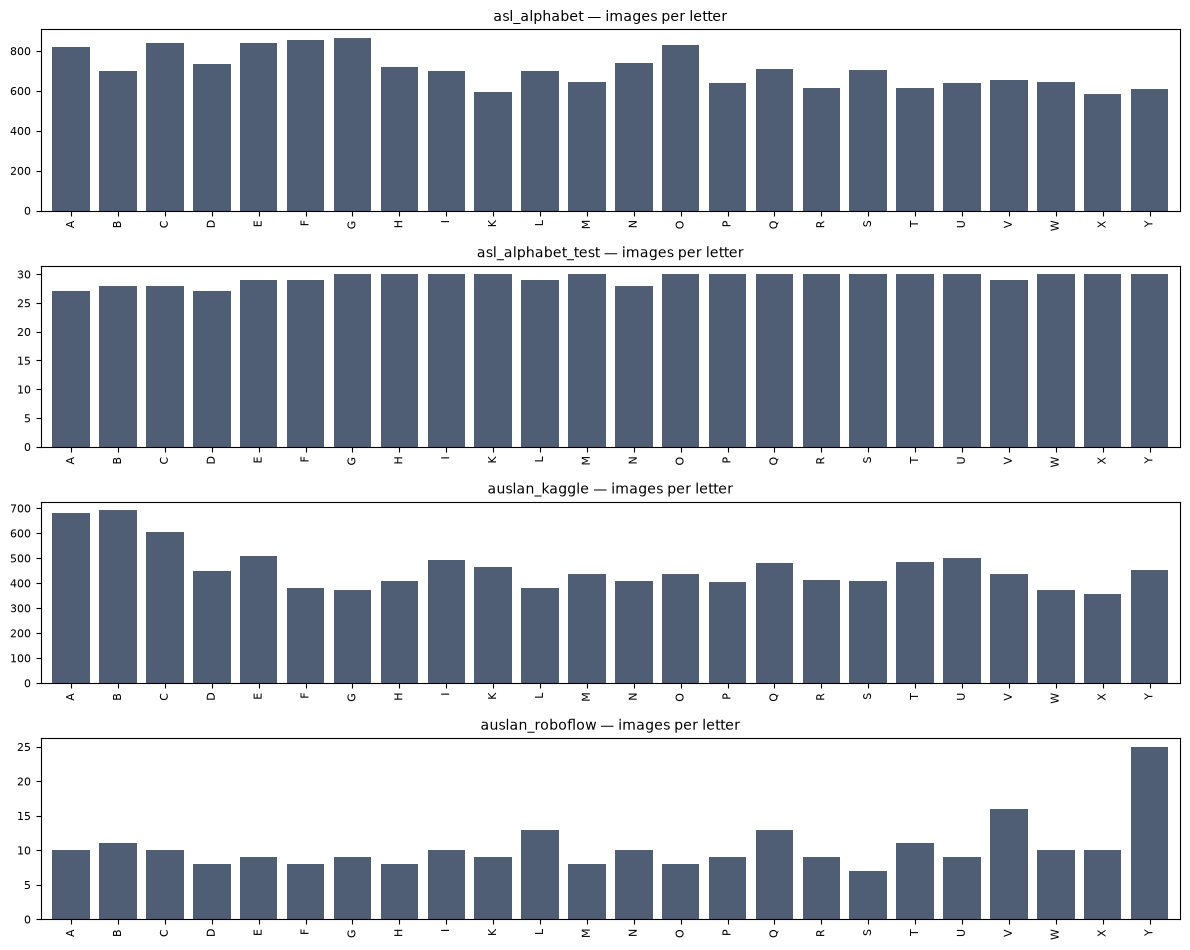

In [22]:
import matplotlib.pyplot as plt

if catalogs:
    summary = pd.DataFrame(
        {
            "images": {name: len(c) for name, c in catalogs.items()},
            "letters": {name: c["label"].nunique() for name, c in catalogs.items()},
            "detection_rate": {name: (c["n_hands"] > 0).mean() for name, c in catalogs.items()},
            "used_fallback": {name: c["used_fallback"].mean() for name, c in catalogs.items()},
        }
    )
    display(summary.style.format({"detection_rate": "{:.1%}", "used_fallback": "{:.1%}"}))

    fig, axes = plt.subplots(len(catalogs), 1, figsize=(12, 2.4 * len(catalogs)), squeeze=False)
    for ax, (name, catalog) in zip(axes.ravel(), catalogs.items()):
        catalog["label"].value_counts().sort_index().plot.bar(ax=ax, color="#4f5d75", width=0.8)
        ax.set_title(f"{name} — images per letter", fontsize=10)
        ax.set_xlabel("")
        ax.tick_params(labelsize=8)
    fig.tight_layout()
    plt.show()

### Sample crops

What the network actually reads. If these look wrong — wrong hand, cropped too tight, mostly
background — every score below is meaningless, so fix this before going further.

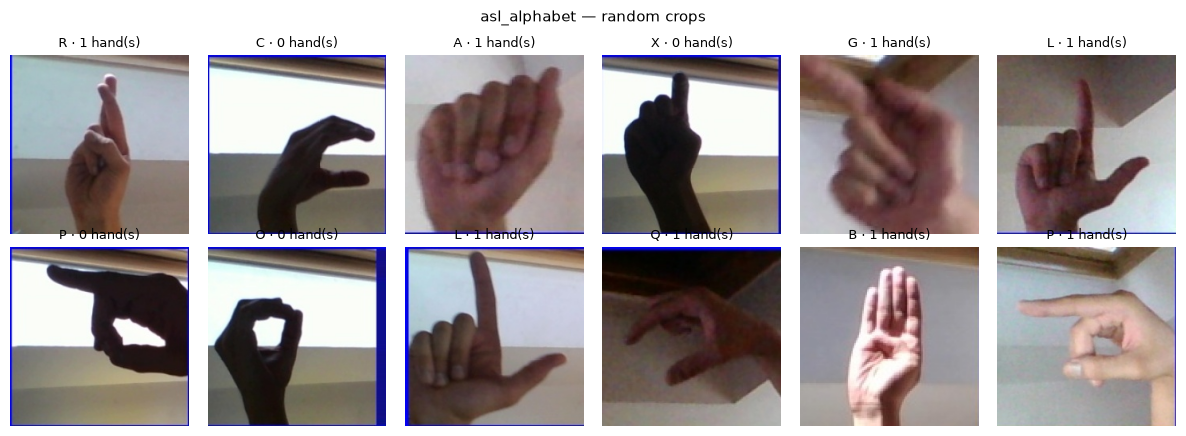

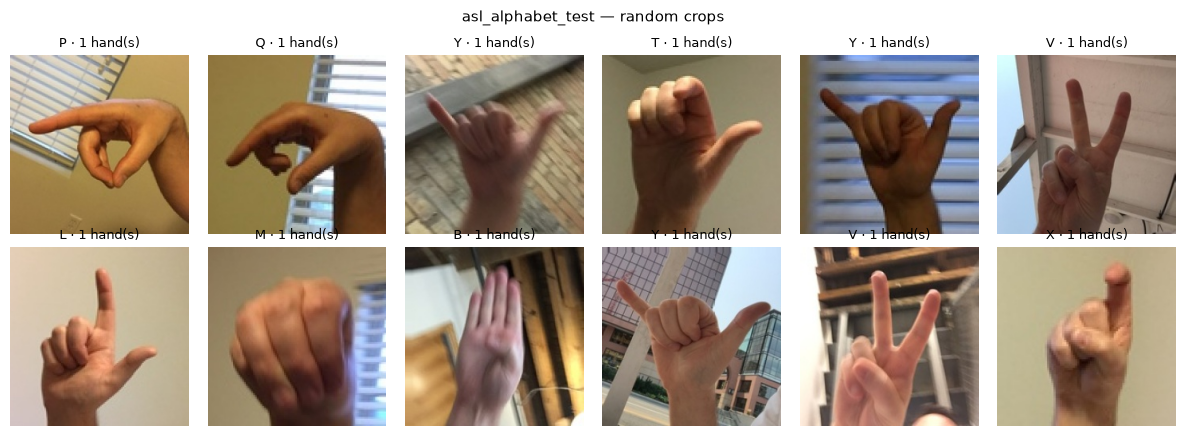

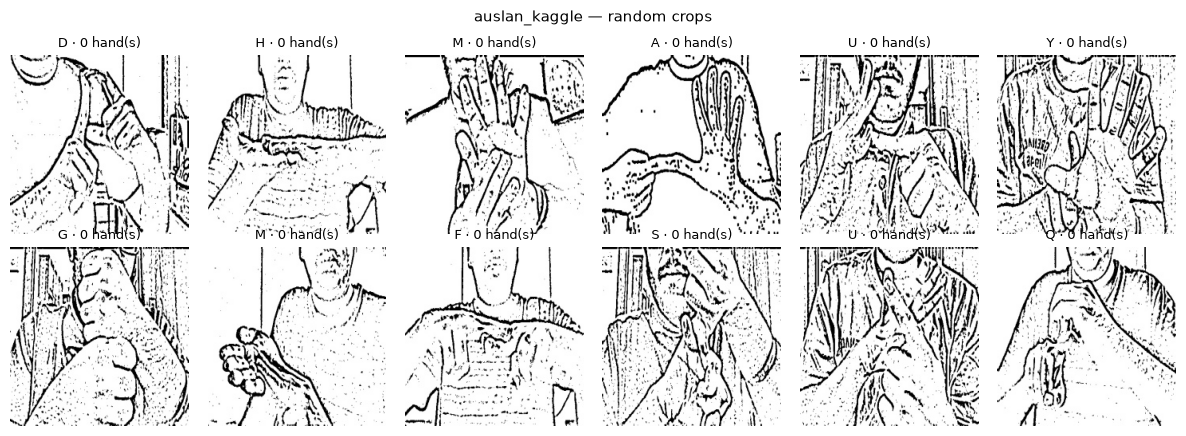

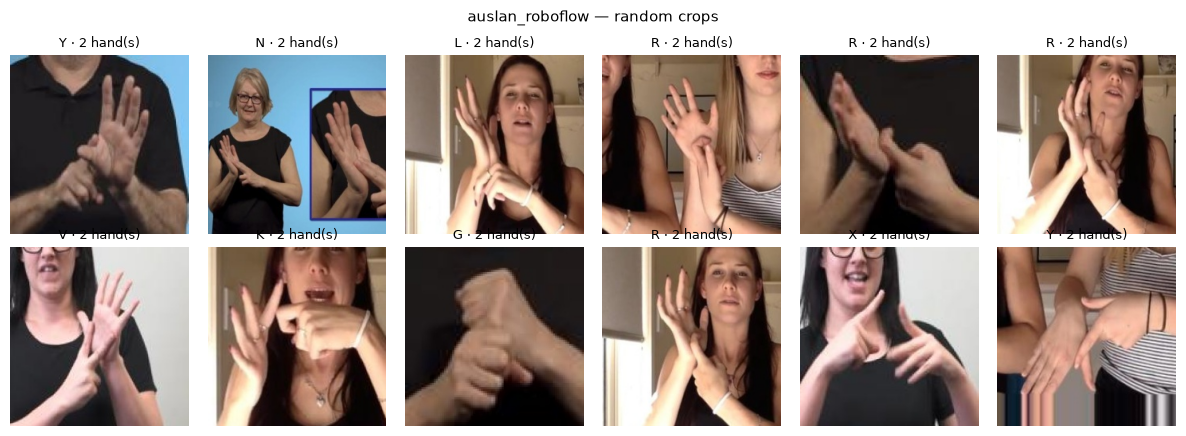

In [23]:
import matplotlib.image as mpimg


def show_crops(catalog: pd.DataFrame, title: str, n: int = 12, seed: int = 0) -> None:
    """Draw a row of cached crops, labelled with the letter and the hand count."""
    sample = catalog.sample(min(n, len(catalog)), random_state=seed)
    columns = 6
    rows = (len(sample) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(2 * columns, 2.2 * rows), squeeze=False)
    for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
        try:
            ax.imshow(mpimg.imread(row["crop_path"]))
        except (FileNotFoundError, OSError):
            ax.text(0.5, 0.5, "missing", ha="center", va="center", fontsize=8)
        ax.set_title(f"{row['label']} · {row['n_hands']} hand(s)", fontsize=9)
    for ax in axes.ravel():
        ax.axis("off")
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    plt.show()


for name, catalog in catalogs.items():
    show_crops(catalog, f"{name} — random crops")

### Where detection failed

Images with no detected hand fall back to a skin-blob guess or the whole frame. Worth seeing
which images those are — it explains a lot of M1 and M5 behaviour later.

asl_alphabet: 3,657 of 16,980 images with no hand found


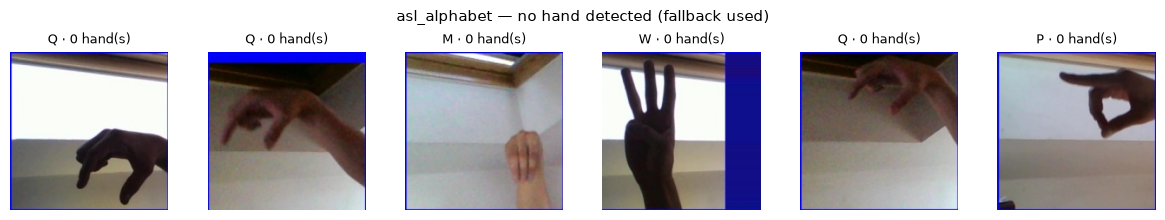

asl_alphabet_test: 26 of 704 images with no hand found


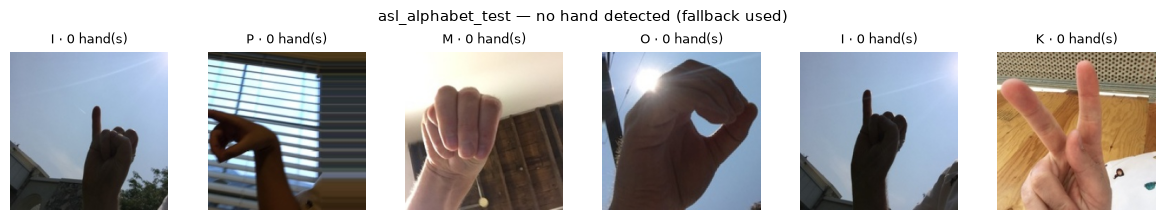

auslan_kaggle: 11,028 of 11,028 images with no hand found


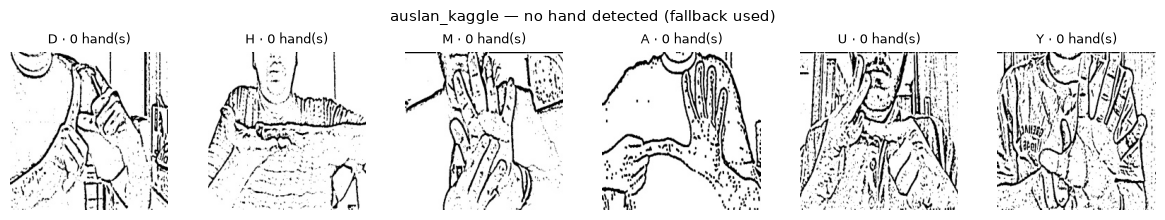

auslan_roboflow: hands found in every image


In [24]:
for name, catalog in catalogs.items():
    failures = catalog[catalog["n_hands"] == 0]
    if failures.empty:
        print(f"{name}: hands found in every image")
        continue
    print(f"{name}: {len(failures):,} of {len(catalog):,} images with no hand found")
    show_crops(failures, f"{name} — no hand detected (fallback used)", n=6)

## 7. Smoke test — one run

Before launching 77 runs (of which about 65 actually train — the rest are skipped because
hand-crafted methods cannot transfer), prove the loop works on the fastest method. `m2_hog_svm` under P1
is hand-crafted features plus an SVM, so it finishes quickly and exercises the whole path:
data bundle, fit, predict, score, store.

In [25]:
import time

from auslan.results import ResultStore, RunSpec
from auslan.runner import Runner

store = ResultStore(settings.artifacts_dir)
runner = Runner(settings, store)

smoke = RunSpec("m2_hog_svm", "P1", seed=0)
print(f"running {smoke.key} ...")

started = time.perf_counter()
ran = runner.run(smoke)
print(f"{'completed' if ran else 'already done (skipped)'} in {time.perf_counter() - started:.1f}s")

display(store.table().query("key == @smoke.key"))

running m2_hog_svm-P1-s0 ...
already done (skipped) in 0.0s


,key,method,protocol,k,seed,tag,test_set,n_train,macro_f1,accuracy,top3,fit_seconds,ms_classify,model_mb
0,m2_hog_svm-P1-s0,m2_hog_svm,P1,NaN,0,,asl_test,11886,0.982758,0.982725,0.993325,251.305153,30.86877,12.570212
1,m2_hog_svm-P1-s0,m2_hog_svm,P1,NaN,0,,asl_cross,11886,0.440103,0.443182,0.678977,251.305153,30.86877,12.570212


## 8. Run E1

The headline experiment: every method under P1, P2 and P3 at k=20, plus P2/P3 on all data once.

**This cell is resumable.** `ResultStore` skips any run already on disk, so if the kernel dies
or you interrupt it, just run the cell again and it picks up where it stopped. Nothing is lost.

Narrow it while you explore — a couple of methods first, the full set once you trust it:

```python
specs = plan("E1", settings, methods=["m2_hog_svm", "m4_resnet18"], seeds=[0], protocols=["P1"])
```

In [26]:
from auslan.experiments import plan

specs = plan("E1", settings)
overview = pd.DataFrame([{"method": s.method, "protocol": s.protocol, "k": s.k} for s in specs])

print(f"{len(specs)} runs planned, {sum(store.has(s.key) for s in specs)} already done\n")
display(pd.crosstab(overview["method"], overview["protocol"], margins=True))

77 runs planned, 21 already done



protocol,P1,P2,P3,All
method,,,,
m1_skin_svm,3,4,4,11
m2_hog_svm,3,4,4,11
m3_cnn,3,4,4,11
m4_mobilenetv2,3,4,4,11
m4_resnet18,3,4,4,11
m5_landmarks_mlp,3,4,4,11
m5_landmarks_svm,3,4,4,11
All,21,28,28,77


In [27]:
from IPython.display import clear_output

todo = [spec for spec in specs if not store.has(spec.key)]
print(f"{len(todo)} runs to go")

started, failures = time.perf_counter(), []
for number, spec in enumerate(todo, 1):
    try:
        runner.run(spec)
    except Exception as error:  # one bad run must not end a multi-hour job
        failures.append((spec.key, f"{type(error).__name__}: {error}"))
    elapsed = time.perf_counter() - started
    per_run = elapsed / number
    clear_output(wait=True)
    print(
        f"[{number}/{len(todo)}] {spec.key}\n"
        f"elapsed {elapsed / 60:.1f} min · {per_run / 60:.1f} min/run · "
        f"eta {(len(todo) - number) * per_run / 60:.0f} min · {len(failures)} failed"
    )
    display(store.table().tail(8))

print(f"\ndone in {(time.perf_counter() - started) / 60:.1f} min")
if failures:
    print(f"\n{len(failures)} runs could not complete:")
    for key, message in failures[:10]:
        print(f"  {key}: {message[:110]}")
    print("\nA missing dataset is the usual cause — P2/P3 need Kaggle Auslan and Roboflow.")

[56/56] m3_cnn-P3-kall-s0
elapsed 72.0 min · 1.3 min/run · eta 0 min · 0 failed


,key,method,protocol,k,seed,tag,test_set,n_train,macro_f1,accuracy,top3,fit_seconds,ms_classify,model_mb
130,m3_cnn-P3-k20-s2,m3_cnn,P3,20.0,2,,roboflow,480,0.007335,0.036000,0.152000,29.337345,7.281586,1.597584
131,m3_cnn-P3-k20-s2,m3_cnn,P3,20.0,2,,roboflow_raw,480,0.006236,0.036000,0.128000,29.337345,7.281586,1.597584
132,m3_cnn-P2-kall-s0,m3_cnn,P2,NaN,0,,kaggle_test,7719,0.619317,0.627795,0.856193,182.583893,7.039126,1.597584
133,m3_cnn-P2-kall-s0,m3_cnn,P2,NaN,0,,roboflow,7719,0.020399,0.052000,0.140000,182.583893,7.039126,1.597584
134,m3_cnn-P2-kall-s0,m3_cnn,P2,NaN,0,,roboflow_raw,7719,0.009059,0.020000,0.080000,182.583893,7.039126,1.597584
135,m3_cnn-P3-kall-s0,m3_cnn,P3,NaN,0,,kaggle_test,7719,0.814209,0.814502,0.947432,274.114188,7.405324,1.597584
136,m3_cnn-P3-kall-s0,m3_cnn,P3,NaN,0,,roboflow,7719,0.017728,0.044000,0.140000,274.114188,7.405324,1.597584
137,m3_cnn-P3-kall-s0,m3_cnn,P3,NaN,0,,roboflow_raw,7719,0.007349,0.024000,0.112000,274.114188,7.405324,1.597584



done in 72.0 min


## 9. Results

Everything below reads `store.table()`, so it works on a partial run — plot whatever has
finished so far rather than waiting for all 78.

In [28]:
table = store.table()
print(f"{len(table)} result rows over {table['key'].nunique()} runs")
print(f"test sets: {sorted(table['test_set'].unique())}")
display(table.head())

138 result rows over 53 runs
test sets: ['asl_cross', 'asl_test', 'kaggle_test', 'roboflow', 'roboflow_raw']


,key,method,protocol,k,seed,tag,test_set,n_train,macro_f1,accuracy,top3,fit_seconds,ms_classify,model_mb
0,m2_hog_svm-P1-s0,m2_hog_svm,P1,NaN,0,,asl_test,11886,0.982758,0.982725,0.993325,251.305153,30.868770,12.570212
1,m2_hog_svm-P1-s0,m2_hog_svm,P1,NaN,0,,asl_cross,11886,0.440103,0.443182,0.678977,251.305153,30.868770,12.570212
2,m1_skin_svm-P1-s0,m1_skin_svm,P1,NaN,0,,asl_test,11886,0.608580,0.609344,0.806046,86.744372,20.343592,3.443702
3,m1_skin_svm-P1-s0,m1_skin_svm,P1,NaN,0,,asl_cross,11886,0.050118,0.065341,0.149148,86.744372,20.343592,3.443702
4,m1_skin_svm-P1-s1,m1_skin_svm,P1,NaN,1,,asl_test,11886,0.608580,0.609344,0.806046,86.353909,20.869298,3.443702


### Method comparison

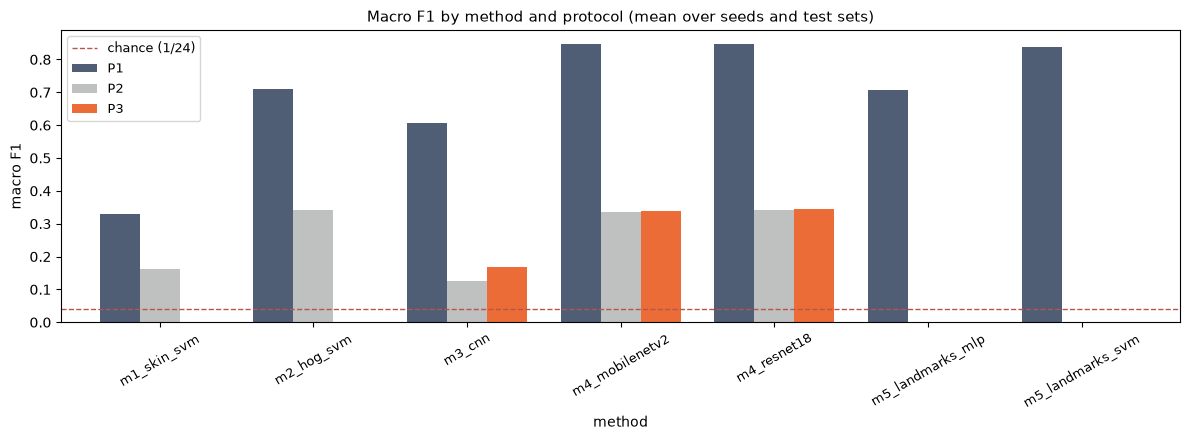

In [29]:
if not table.empty:
    headline = table[table["k"].isna() | (table["k"] == 20)]
    pivot = headline.pivot_table(
        index="method", columns=["protocol", "test_set"], values="macro_f1", aggfunc="mean"
    )
    display(pivot.style.format("{:.3f}", na_rep="—").background_gradient(cmap="Blues", axis=None))

    fig, ax = plt.subplots(figsize=(12, 4.5))
    headline.pivot_table(
        index="method", columns="protocol", values="macro_f1", aggfunc="mean"
    ).plot.bar(ax=ax, width=0.78, color=["#4f5d75", "#bfc0c0", "#eb6c36"])
    ax.set_ylabel("macro F1")
    ax.set_title("Macro F1 by method and protocol (mean over seeds and test sets)", fontsize=11)
    ax.axhline(1 / 24, color="#b85450", linestyle="--", linewidth=1, label="chance (1/24)")
    ax.legend(fontsize=9)
    ax.tick_params(axis="x", rotation=30, labelsize=9)
    fig.tight_layout()
    plt.show()

### The research question: does ASL training help?

P2 and P3 are identical apart from the starting weights, so `P3 − P2` on the same method,
k, seed and test set **is** the transfer effect. Positive means ASL pre-training helped.

,mean,std,count
method,,,
m3_cnn,+0.036,0.055,9
m4_mobilenetv2,-0.002,0.012,9
m4_resnet18,+0.003,0.036,9


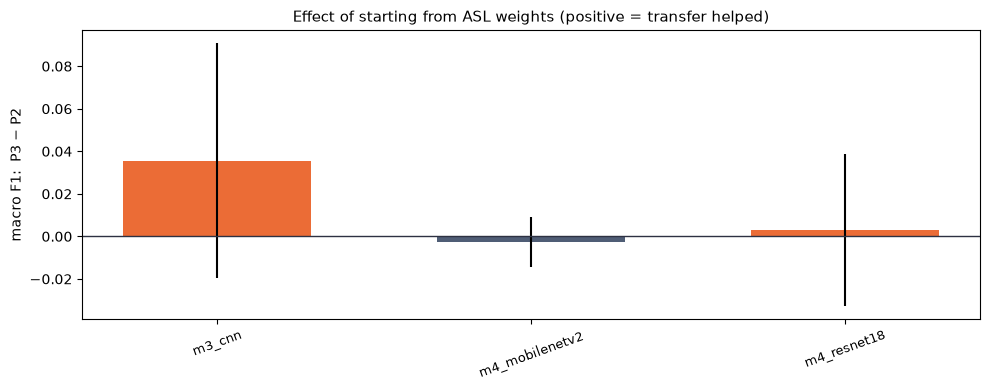

In [30]:
if not table.empty:
    keys = ["method", "k", "seed", "test_set"]
    paired = (
        table[table["protocol"].isin(["P2", "P3"])]
        .pivot_table(index=keys, columns="protocol", values="macro_f1")
        .dropna()
        .reset_index()
    )
    if paired.empty:
        print("no paired P2/P3 results yet — transfer-capable methods are M3, M4 and M5-MLP")
    else:
        paired["delta"] = paired["P3"] - paired["P2"]
        effect = paired.groupby("method")["delta"].agg(["mean", "std", "count"])
        display(effect.style.format({"mean": "{:+.3f}", "std": "{:.3f}"}))

        fig, ax = plt.subplots(figsize=(10, 4))
        colours = ["#eb6c36" if value > 0 else "#4f5d75" for value in effect["mean"]]
        ax.bar(effect.index, effect["mean"], yerr=effect["std"], color=colours, width=0.6)
        ax.axhline(0, color="#2d3142", linewidth=1)
        ax.set_ylabel("macro F1:  P3 − P2")
        ax.set_title("Effect of starting from ASL weights (positive = transfer helped)", fontsize=11)
        ax.tick_params(axis="x", rotation=20, labelsize=9)
        fig.tight_layout()
        plt.show()

### Confusion matrix

Which letters get mistaken for which. Change `inspect_key` to look at any finished run.

best so far: m2_hog_svm-P2-kall-s0 on kaggle_test  (macro F1 0.998)


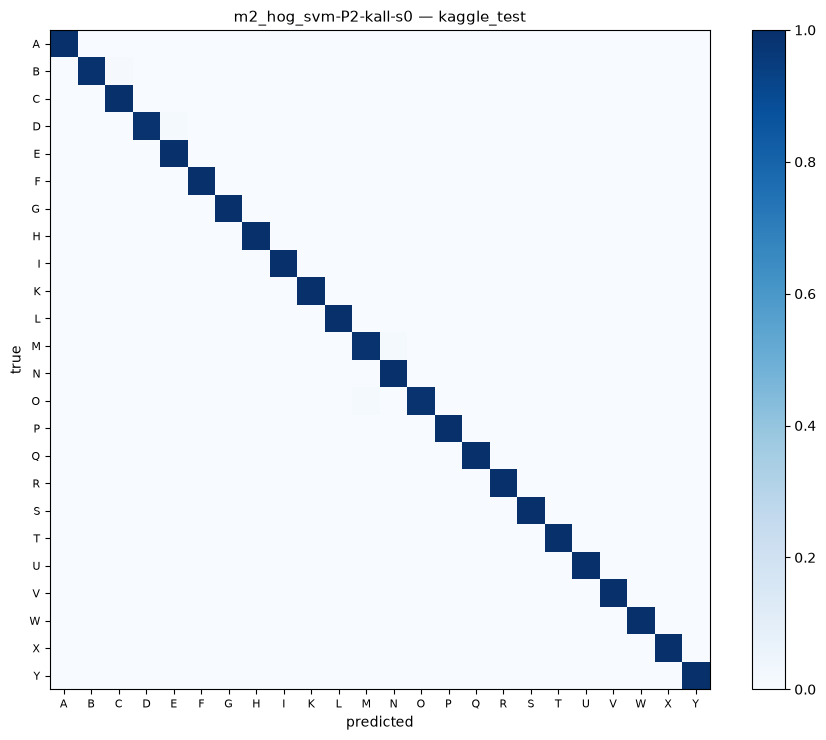


most confused pairs:
  B read as C: 1
  O read as M: 1
  M read as N: 1
  D read as E: 1


In [31]:
import numpy as np

# Both languages use the same 24 letters: J and Z need movement, which one image cannot show.
from auslan.data.classes import ASL_LETTERS

if not table.empty:
    best = table.sort_values("macro_f1", ascending=False).iloc[0]
    inspect_key, inspect_set = best["key"], best["test_set"]
    print(f"best so far: {inspect_key} on {inspect_set}  (macro F1 {best['macro_f1']:.3f})")

    y_true, proba = store.predictions(inspect_key, inspect_set)
    y_pred = proba.argmax(axis=1)

    n = proba.shape[1]
    labels = ASL_LETTERS[:n]
    confusion = np.zeros((n, n), dtype=int)
    for true_index, predicted_index in zip(y_true, y_pred):
        confusion[true_index, predicted_index] += 1
    normalised = confusion / np.clip(confusion.sum(axis=1, keepdims=True), 1, None)

    fig, ax = plt.subplots(figsize=(9, 7.5))
    image = ax.imshow(normalised, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(n), labels, fontsize=8)
    ax.set_yticks(range(n), labels, fontsize=8)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(f"{inspect_key} — {inspect_set}", fontsize=11)
    fig.colorbar(image, ax=ax, fraction=0.045)
    fig.tight_layout()
    plt.show()

    off_diagonal = confusion - np.diag(np.diag(confusion))
    worst = np.dstack(np.unravel_index(np.argsort(-off_diagonal, axis=None), off_diagonal.shape))[0]
    print("\nmost confused pairs:")
    for true_index, predicted_index in worst[:8]:
        count = off_diagonal[true_index, predicted_index]
        if count:
            print(f"  {labels[true_index]} read as {labels[predicted_index]}: {count}")

### Cost against accuracy

Training time and model size matter for the tutoring use case — a method that wins by a
point but takes ten times as long may not be the one to ship.

,macro_f1,fit_minutes,ms_per_frame,model_mb
method,,,,
m1_skin_svm,0.219,0.750,18.190,1.572
m2_hog_svm,0.466,1.677,25.546,8.362
m3_cnn,0.238,2.537,10.215,1.598
m4_mobilenetv2,0.439,1.319,19.706,9.282
m4_resnet18,0.444,1.351,21.314,44.842
m5_landmarks_mlp,0.708,0.099,1.490,0.339
m5_landmarks_svm,0.838,0.609,16.245,6.857


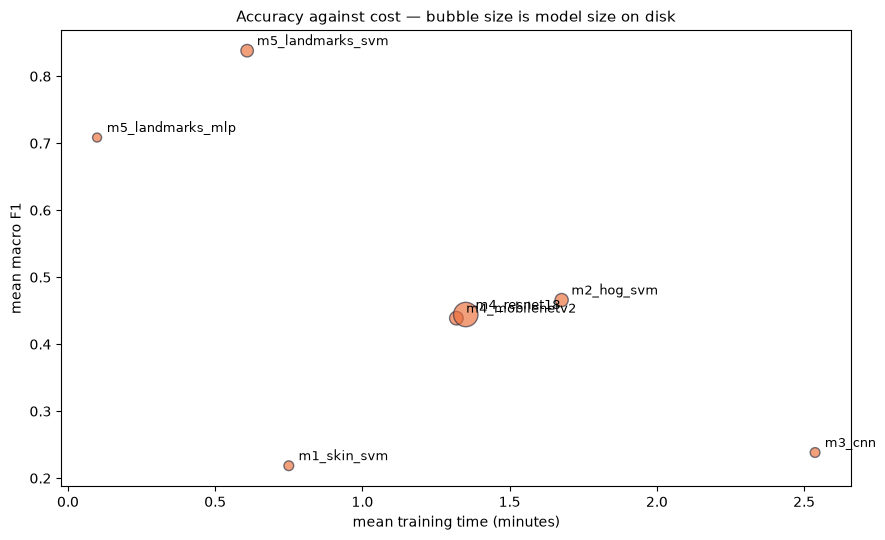

In [32]:
if not table.empty:
    cost = table.groupby("method").agg(
        macro_f1=("macro_f1", "mean"),
        fit_minutes=("fit_seconds", lambda s: s.mean() / 60),
        ms_per_frame=("ms_classify", "mean"),
        model_mb=("model_mb", "mean"),
    )
    display(cost.style.format("{:.3f}"))

    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.scatter(cost["fit_minutes"], cost["macro_f1"], s=cost["model_mb"] * 6 + 40, color="#eb6c36",
               alpha=0.65, edgecolor="#2d3142")
    for method, row in cost.iterrows():
        ax.annotate(method, (row["fit_minutes"], row["macro_f1"]),
                    textcoords="offset points", xytext=(7, 4), fontsize=9)
    ax.set_xlabel("mean training time (minutes)")
    ax.set_ylabel("mean macro F1")
    ax.set_title("Accuracy against cost — bubble size is model size on disk", fontsize=11)
    fig.tight_layout()
    plt.show()

## 10. Build the report and save to `results/tong/`

`build_report` writes the Task 2 tables — Table 9 with bootstrap intervals, significance tests,
per-letter F1, the k curve, success criteria. The export then copies them into
`results/tong/e1/`, matching the repo convention of one folder per person's run.

### Time the hand detector first

The cost table and success criteria S2/S4 need milliseconds per frame, which only this step
measures. Run it before `build_report` or those columns come out empty. It times 50 sampled
frames on the CPU, deliberately: that is what a laptop tutoring app would actually do.

In [33]:
import json

import pandas as pd

from auslan.evaluation.speed import crop_ms
from auslan.report import CROP_TIMING_FILE

# cost.md needs the hand-detection time per frame. Without it the "detect+crop ms" column reads
# 0.0, "frames/s" stays empty, and success criteria S2/S4 cannot be checked at all.
timing_set = "auslan_roboflow"
if not (settings.work_dir / timing_set / "hashed.csv").exists():
    print(f"{timing_set} is not prepared; timing on asl_alphabet_test photos instead")
    timing_set = "asl_alphabet_test"

paths = pd.read_csv(settings.work_dir / timing_set / "hashed.csv")["path"].tolist()
cropper = build_cropper(settings.models_dir, "skin", settings.crop_size)
milliseconds = crop_ms(cropper, paths)  # 50 sampled frames, a couple of seconds

target = settings.artifacts_dir / CROP_TIMING_FILE
target.parent.mkdir(parents=True, exist_ok=True)
target.write_text(json.dumps({"crop_ms": milliseconds}), encoding="utf-8")
print(f"hand detection + cropping: {milliseconds:.1f} ms per frame  ->  {target}")

hand detection + cropping: 40.7 ms per frame  ->  artifacts\crop_ms.json


In [34]:
from auslan.report import build_report

report_folder = build_report(store, settings)
print(f"report written to {report_folder}\n")
for path in sorted(report_folder.iterdir()):
    print(f"  {path.name:28s} {path.stat().st_size / 1024:7.1f} KB")

report written to artifacts\report

  confused_pairs.md                0.4 KB
  confusion_m1_skin_svm.csv        1.2 KB
  confusion_m2_hog_svm.csv         1.3 KB
  confusion_m3_cnn.csv             1.3 KB
  confusion_m4_mobilenetv2.csv     1.3 KB
  confusion_m4_resnet18.csv        1.2 KB
  cost.md                          0.5 KB
  cross_dataset.md                 0.8 KB
  detection_rates.md               0.5 KB
  image_size.md                    0.3 KB
  index.html                      13.1 KB
  k_curve.csv                      0.8 KB
  per_letter_f1.csv                1.8 KB
  results.csv                     20.6 KB
  significance.md                  1.4 KB
  style_effect.md                  0.4 KB
  success_criteria.md              0.7 KB
  table9.md                        1.0 KB
  variants.md                      0.1 KB


In [35]:
import shutil

PERSON, EXPERIMENT = "tong", "e1"
destination = ROOT / "results" / PERSON / EXPERIMENT
destination.mkdir(parents=True, exist_ok=True)

shutil.copytree(report_folder, destination, dirs_exist_ok=True)
shutil.copy2(settings.artifacts_dir / "results.jsonl", destination / "results.jsonl")

notes = destination / "README.md"
if not notes.exists():
    notes.write_text(
        f"# {PERSON.title()} — {EXPERIMENT.upper()}\n\n"
        f"Run from `notebooks/auslan_lab.ipynb` on a {torch.cuda.get_device_name(0)}"
        f" ({torch.__version__}).\n\n"
        f"Covers {table['key'].nunique()} runs across protocols "
        f"{sorted(table['protocol'].unique())}.\n\n"
        "Note: trained on CUDA, so figures differ in the last decimals from a CPU or MPS run.\n",
        encoding="utf-8",
    )

print(f"copied to {destination}")
for path in sorted(destination.iterdir()):
    print(f"  {path.name}")

copied to D:\Master degree at UTS\Study\2nd sem1\UTS Image Processing and Pattern Recognition\Assignment\Final Project\auslan-image-processing\results\tong\e1
  confused_pairs.md
  confusion_m1_skin_svm.csv
  confusion_m2_hog_svm.csv
  confusion_m3_cnn.csv
  confusion_m4_mobilenetv2.csv
  confusion_m4_resnet18.csv
  cost.md
  cross_dataset.md
  detection_rates.md
  image_size.md
  index.html
  k_curve.csv
  per_letter_f1.csv
  README.md
  results.csv
  results.jsonl
  significance.md
  style_effect.md
  success_criteria.md
  table9.md
  variants.md
